[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fxzhou22/DiffRhythm/blob/main/notebooks/DiffRhythm_colab.ipynb)

# DiffRhythm 谛韵 Colab session 🎹

Blazingly Fast and Embarrassingly Simple
End-to-End Full-Length Song Generation with Latent Diffusion

Github: https://github.com/ASLP-lab/DiffRhythm

Hugging face spaces: https://huggingface.co/spaces/ASLP-lab/DiffRhythm

This notebook clones the project from Github, and provides simple inference as shown in their README.

## Architecture (image on README page)

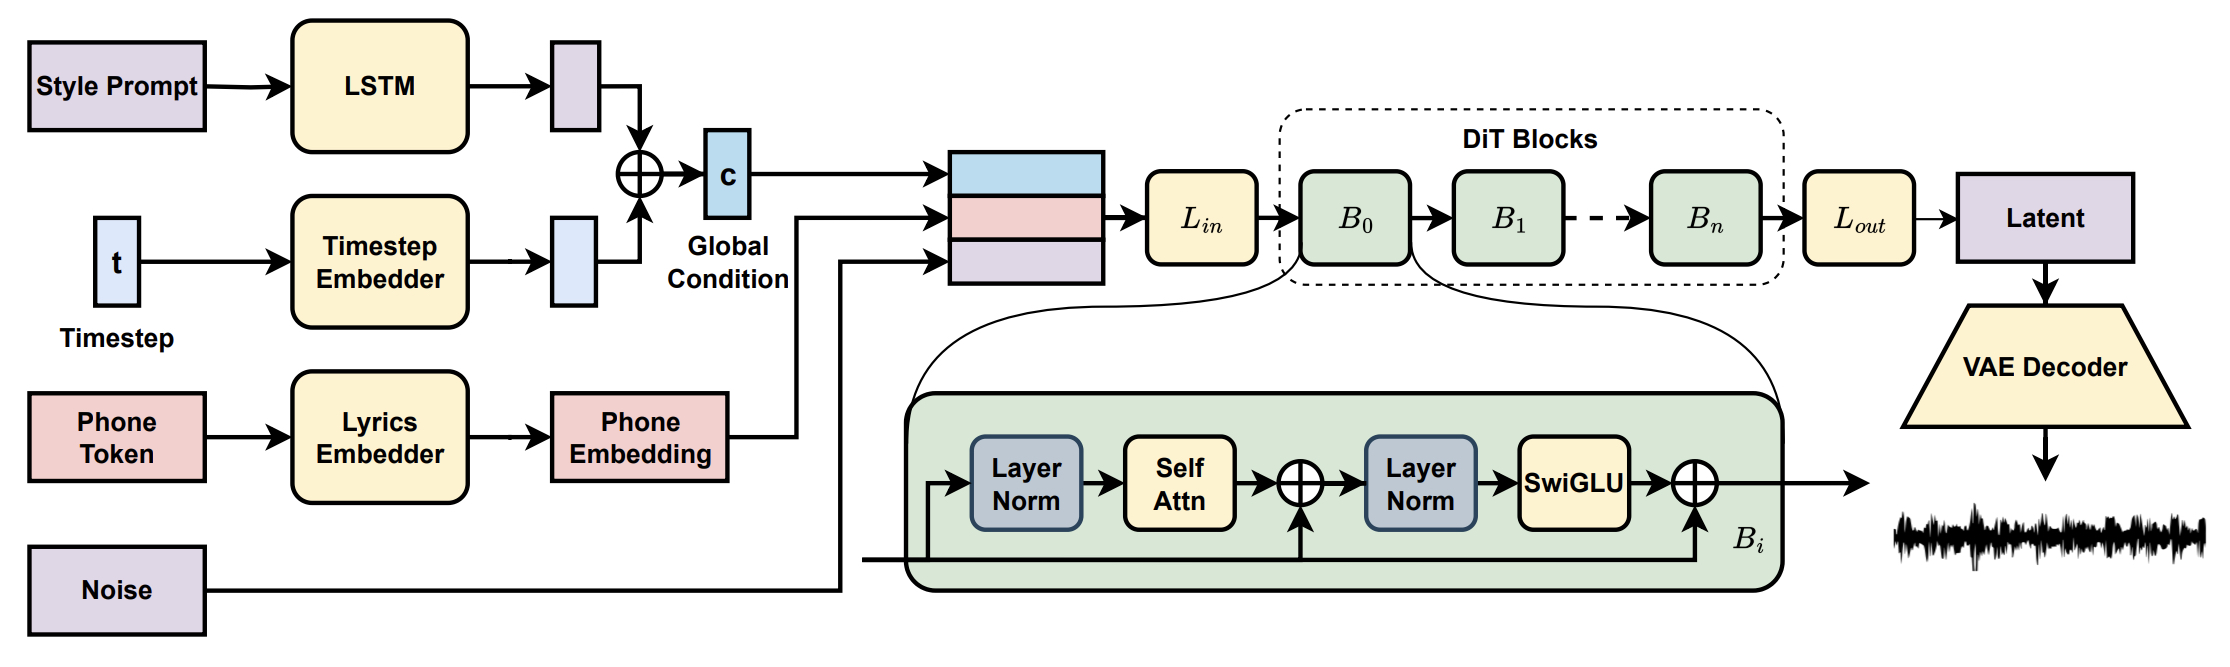

*Don't forget to activate Colab's free GPU runtime, otherwise you may take longer time for inference, and reload runtime when you activate it later.*

## Check GPU

In [ ]:
import torch
print("GPU available :", torch.cuda.is_available())
print("Name of GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")


## Clone the repository

In [ ]:
# Clone from github
!git clone https://github.com/ASLP-lab/DiffRhythm.git

## Check out Colab distribution type

In [ ]:
!cat /etc/os-release

It's an Ubuntu, we can thus install `espeak-ng` with `apt-get`.

## What is eSpeak NG?

eSpeak NG is an open source speech synthesizer that supports more than hundred languages and accents.

https://github.com/espeak-ng/espeak-ng

In [ ]:
!sudo apt-get install espeak-ng

Check the installation

In [ ]:
!apt show espeak-ng

In [ ]:
!which espeak-ng

## Create virtual environment

In Google Colab, each session provides a clean and isolated Python environment, so creating a virtual environment with `venv` or `conda` isn't always strictly necessary.

In addition, `conda` is not pre-installed.

And running
```bash
!python3 -m venv venv_diffrhythm
```
gives


> Error: Command '['/content/venv_diffrhythm/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.

So let's proceed directly into installing requirements





## Check out the contents of requirements.txt

In [ ]:
!cat DiffRhythm/requirements.txt

In [ ]:
!pip install -r DiffRhythm/requirements.txt


For the time being, I'm receving this warning:

>   WARNING: The following packages were previously imported in this runtime:
    [argparse]
  You must restart the runtime in order to use newly installed versions.
  Restarting will lose all runtime state, including local variables.

This is because `prefigure` is requiring `argparse`

> Collecting argparse (from prefigure==0.0.10->-r DiffRhythm/requirements.txt (line 11))
  Using cached argparse-1.4.0-py2.py3-none-any.whl.metadata (2.8 kB)


while the latter is already a standard Python library, the runtime had an `argparse` module loaded when `pip` tried to install or update it.

Restarting as demanded by Colab dosen't solve it. However, this doesn't affect our later inference work, so don't worry, **no need to restart**. (I tried the inference and then completed this remark.)  

I opened an issue on https://github.com/drscotthawley/prefigure/issues/2, the developpers of `prefigure` may solve it.



## Run inference

**Before you start** Notice that the two inference script saves actually save their output to the same `output.wav`, meaning that a new inference overwrites the old one. Either change the inference scripts, or make a copy if you do like a save for each inference.

**Good news** Colab keeps the output memory when you do `display(Audio("/content/DiffRhythm/infer/example/output/output.wav"))`, so you can always listen the correspond output (just the result, dont relance the code) if you attach it right after your inference...




### 1. Inference with WAV file

In [ ]:
!bash DiffRhythm/scripts/infer_wav_ref.sh

In [ ]:
!cat DiffRhythm/scripts/infer_wav_ref.sh

The output file is in `infer/example/output`, let's listen to it 🎵

In [ ]:
from IPython.display import Audio, display

display(Audio("/content/DiffRhythm/infer/example/output/output.wav"))

And here's the referenced audio

In [ ]:
display(Audio("/content/DiffRhythm/infer/example/eg_en.mp3"))

### 2. Inference with text prompt

In [ ]:
!bash DiffRhythm/scripts/infer_prompt_ref.sh

In [ ]:
!cat DiffRhythm/scripts/infer_prompt_ref.sh

Reference prompt: folk, acoustic guitar, harmonica, touching.

Let's listen to it 🎶

In [ ]:
display(Audio("/content/DiffRhythm/infer/example/output/output.wav"))

Hope this notebook helps you and you enjoyed the DiffRhythm model! 😸